# Sales Data Analysis Using Python and SQL

## 1. Business Problem and Project Objectives

### Business Problem
Analyze retail sales data to understand sales performance,
customer behavior, product profitability, and regional trends.

### Project Objectives
- Analyze overall sales and profit.
- Identify top-performing products and categories.
- Understand customer purchasing patterns.
- Evaluate regional sales performance.
- Generate actionable business insights using Python and SQL.

In [1]:
# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization appearance
sns.set_theme(style="whitegrid")

# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the sales dataset using Windows-compatible encoding

df = pd.read_csv(
    "../data/raw/sales.csv",
    encoding="cp1252"
)

# Display the first five records
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,03-01-2023,07-01-2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,05-01-2023,12-01-2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


## 2. Dataset Understanding

The dataset contains retail sales transaction records.

It includes information about:
- Orders and shipping details
- Customer names and segments
- Product categories and sub-categories
- Sales, quantity, discounts, and profit
- Geographical information such as city, state, and region

The objective of this step is to understand the dataset's structure, number of records, columns, and data types before performing data cleaning.

In [3]:
# Display the dataset dimensions
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (10194, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  str    
 2   Order Date      10194 non-null  str    
 3   Ship Date       10194 non-null  str    
 4   Ship Mode       10194 non-null  str    
 5   Customer ID     10194 non-null  str    
 6   Customer Name   10194 non-null  str    
 7   Segment         10194 non-null  str    
 8   Country/Region  10194 non-null  str    
 9   City            10194 non-null  str    
 10  State/Province  1

## 3. Data Quality Assessment

In this step, we examine the dataset for potential data quality issues.

The assessment includes:
- Missing values
- Duplicate records
- Unique customers, orders, and products

These checks help us understand the quality of the raw dataset before making any changes.

In [4]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check the total number of missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0


In [5]:
# Count unique business entities
print("Unique Orders:", df["Order ID"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())
print("Unique Products:", df["Product ID"].nunique())

# Count unique categories and regions
print("Unique Categories:", df["Category"].nunique())
print("Unique Sub-Categories:", df["Sub-Category"].nunique())
print("Unique Regions:", df["Region"].nunique())

Unique Orders: 5111
Unique Customers: 804
Unique Products: 1862
Unique Categories: 3
Unique Sub-Categories: 17
Unique Regions: 4


In [6]:
# Inspect unique values in important categorical columns

categorical_columns = [
    "Ship Mode",
    "Segment",
    "Category",
    "Sub-Category",
    "Region"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Ship Mode:
<StringArray>
['Standard Class', 'First Class', 'Second Class', 'Same Day']
Length: 4, dtype: str

Segment:
<StringArray>
['Consumer', 'Home Office', 'Corporate']
Length: 3, dtype: str

Category:
<StringArray>
['Office Supplies', 'Furniture', 'Technology']
Length: 3, dtype: str

Sub-Category:
<StringArray>
[      'Paper',     'Binders',      'Labels',     'Storage',         'Art',
      'Chairs',   'Fasteners',      'Phones', 'Furnishings', 'Accessories',
   'Bookcases',   'Envelopes',  'Appliances',      'Tables',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str

Region:
<StringArray>
['Central', 'East', 'South', 'West']
Length: 4, dtype: str


In [7]:
# Inspect date values
print("Order Date:")
print(df["Order Date"].head(10))

print("\nShip Date:")
print(df["Ship Date"].head(10))

Order Date:
0    03-01-2023
1    04-01-2023
2    04-01-2023
3    04-01-2023
4    05-01-2023
5    06-01-2023
6    06-01-2023
7    06-01-2023
8    06-01-2023
9    06-01-2023
Name: Order Date, dtype: str

Ship Date:
0    07-01-2023
1    08-01-2023
2    08-01-2023
3    08-01-2023
4    12-01-2023
5    10-01-2023
6    10-01-2023
7    07-01-2023
8    10-01-2023
9    10-01-2023
Name: Ship Date, dtype: str


In [8]:
# Check whether the first or second date component exceeds 12

for column in ["Order Date", "Ship Date"]:
    first_part = df[column].str.split("-").str[0].astype(int)
    second_part = df[column].str.split("-").str[1].astype(int)

    print(f"\n{column}")
    print("First component greater than 12:", (first_part > 12).sum())
    print("Second component greater than 12:", (second_part > 12).sum())


Order Date
First component greater than 12: 6064
Second component greater than 12: 0

Ship Date
First component greater than 12: 6206
Second component greater than 12: 0


In [9]:
# Convert date columns from strings to datetime

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y"
)

# Verify the converted data types
print(df[["Order Date", "Ship Date"]].dtypes)

# Display the converted dates
df[["Order Date", "Ship Date"]].head()

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


,Order Date,Ship Date
0,2023-01-03,2023-01-07
1,2023-01-04,2023-01-08
2,2023-01-04,2023-01-08
3,2023-01-04,2023-01-08
4,2023-01-05,2023-01-12


In [10]:
# Validate shipping dates

invalid_shipping_dates = df[
    df["Ship Date"] < df["Order Date"]
]

print("Invalid Shipping Date Records:", len(invalid_shipping_dates))

assert invalid_shipping_dates.empty, "Invalid shipping dates found"

print("Shipping date validation passed.")

Invalid Shipping Date Records: 0
Shipping date validation passed.


In [11]:
# Calculate the number of days between order date and ship date

df["Shipping Duration"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Display the shipping duration for the first five records
df[["Order Date", "Ship Date", "Shipping Duration"]].head()

,Order Date,Ship Date,Shipping Duration
0,2023-01-03,2023-01-07,4
1,2023-01-04,2023-01-08,4
2,2023-01-04,2023-01-08,4
3,2023-01-04,2023-01-08,4
4,2023-01-05,2023-01-12,7


In [12]:
# Generate descriptive statistics for numerical columns

df[["Sales", "Quantity", "Discount", "Profit", "Shipping Duration"]].describe()

,Sales,Quantity,Discount,Profit,Shipping Duration
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417,3.961350
std,619.906839,2.228317,0.206249,232.465115,1.742829
min,0.444000,1.000000,0.000000,-6599.978000,0.000000
25%,17.220000,2.000000,0.000000,1.760800,3.000000
50%,53.910000,3.000000,0.200000,8.690000,4.000000
75%,209.500000,5.000000,0.200000,29.297925,5.000000
max,22638.480000,14.000000,0.800000,8399.976000,11.000000


In [13]:
# Check unusual numerical values

print("Negative Profit Records:", (df["Profit"] < 0).sum())

print("Zero Profit Records:", (df["Profit"] == 0).sum())

print("Zero Sales Records:", (df["Sales"] == 0).sum())

print("Non-positive Quantity Records:", (df["Quantity"] <= 0).sum())

print("Discount Above 80%:", (df["Discount"] > 0.8).sum())

Negative Profit Records: 1901
Zero Profit Records: 65
Zero Sales Records: 0
Non-positive Quantity Records: 0
Discount Above 80%: 0


In [14]:

# Validate identifier uniqueness

duplicate_row_ids = df["Row ID"].duplicated().sum()

print("Duplicate Row IDs:", duplicate_row_ids)
print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())
print("Duplicate Customer IDs:", df["Customer ID"].duplicated().sum())
print("Duplicate Product IDs:", df["Product ID"].duplicated().sum())

assert duplicate_row_ids == 0, "Row IDs must be unique"

print("Row ID uniqueness validation passed.")


Duplicate Row IDs: 0
Duplicate Order IDs: 5083
Duplicate Customer IDs: 9390
Duplicate Product IDs: 8332
Row ID uniqueness validation passed.


In [15]:

# Validate Row ID sequence

expected_row_ids = np.arange(1, len(df) + 1)

print("Minimum Row ID:", df["Row ID"].min())
print("Maximum Row ID:", df["Row ID"].max())
print("Number of Unique Row IDs:", df["Row ID"].nunique())

assert df["Row ID"].is_monotonic_increasing, "Row IDs are not in increasing order"
assert np.array_equal(df["Row ID"].to_numpy(), expected_row_ids), "Row IDs contain gaps or unexpected values"

print("Row ID sequence validation passed.")


Minimum Row ID: 1
Maximum Row ID: 10194
Number of Unique Row IDs: 10194
Row ID sequence validation passed.


In [16]:
# Check leading and trailing whitespace in text columns
text_columns = df.select_dtypes(include="object").columns

total_whitespace = sum(
    df[col].astype("string").str.strip().ne(
        df[col].astype("string")
    ).sum()
    for col in text_columns
)

# Check empty strings in text columns
total_empty_strings = sum(
    df[col].astype("string").str.strip().eq("").sum()
    for col in text_columns
)

print("Leading/Trailing Whitespace:", total_whitespace)
print("Empty Strings:", total_empty_strings)

# Validate text consistency
assert total_whitespace == 0, "Leading or trailing whitespace found"
assert total_empty_strings == 0, "Empty strings found"

print("Text consistency validation passed.")

C:\Users\DELL\AppData\Local\Temp\ipykernel_9396\4058032434.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


Leading/Trailing Whitespace: 0
Empty Strings: 0
Text consistency validation passed.


In [17]:
# Check the date ranges

print("Earliest Order Date:", df["Order Date"].min())
print("Latest Order Date:", df["Order Date"].max())

print("\nEarliest Ship Date:", df["Ship Date"].min())
print("Latest Ship Date:", df["Ship Date"].max())

Earliest Order Date: 2023-01-03 00:00:00
Latest Order Date: 2026-12-30 00:00:00

Earliest Ship Date: 2023-01-07 00:00:00
Latest Ship Date: 2027-01-05 00:00:00


In [18]:
# Extract the year from Order Date
df["Order Year"] = df["Order Date"].dt.year

# Count records for each year
print(df["Order Year"].value_counts().sort_index())

Order Year
2023    2051
2024    2130
2025    2634
2026    3379
Name: count, dtype: int64


In [19]:
# Extract the shipping year
df["Ship Year"] = df["Ship Date"].dt.year

# Count records where order year and shipping year differ
different_year_records = (
    df["Order Year"] != df["Ship Year"]
).sum()

print("Records with different Order and Ship Years:", different_year_records)

Records with different Order and Ship Years: 166


In [20]:
# Display records where order year and shipping year differ

df.loc[
    df["Order Year"] != df["Ship Year"],
    ["Order ID", "Order Date", "Ship Date", "Order Year", "Ship Year"]
].head(10)

,Order ID,Order Date,Ship Date,Order Year,Ship Year
1975,US-2023-168473,2023-12-26,2024-01-01,2023,2024
1979,US-2023-106334,2023-12-27,2024-01-02,2023,2024
1981,US-2023-159611,2023-12-27,2024-01-01,2023,2024
1988,US-2023-153087,2023-12-27,2024-01-03,2023,2024
1989,US-2023-106334,2023-12-27,2024-01-02,2023,2024
1991,US-2023-159611,2023-12-27,2024-01-01,2023,2024
1993,US-2023-153087,2023-12-27,2024-01-03,2023,2024
1994,US-2023-141313,2023-12-28,2024-01-01,2023,2024
1996,US-2023-141313,2023-12-28,2024-01-01,2023,2024
1997,US-2023-141313,2023-12-28,2024-01-01,2023,2024


## 4. Data Cleaning and Preparation

In this stage, we prepare the raw sales dataset for further analysis.

The objective is to improve data consistency, create useful analytical features, and ensure that the dataset is ready for Exploratory Data Analysis (EDA) and SQL analysis.

### Data Preparation Tasks

- Create a separate working copy of the raw dataset.
- Verify and standardize data types.
- Standardize text columns.
- Validate numerical values.
- Extract useful date features.
- Calculate shipping duration.
- Categorize shipping performance.
- Perform final data validation.
- Export the cleaned dataset for further analysis.

### Expected Outcome

A cleaned and validated dataset containing 10,194 records and 28 columns, ready for further business analysis.

In [21]:
# Create a separate working copy of the raw dataset

sales_df = df.copy()

# Check the dimensions of the working dataset
print("Working Dataset Shape:", sales_df.shape)

# Verify that the original dataset remains unchanged
print("Original Dataset Shape:", df.shape)

Working Dataset Shape: (10194, 24)
Original Dataset Shape: (10194, 24)


In [22]:
# Check data types in the working dataset
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Row ID             10194 non-null  int64         
 1   Order ID           10194 non-null  str           
 2   Order Date         10194 non-null  datetime64[us]
 3   Ship Date          10194 non-null  datetime64[us]
 4   Ship Mode          10194 non-null  str           
 5   Customer ID        10194 non-null  str           
 6   Customer Name      10194 non-null  str           
 7   Segment            10194 non-null  str           
 8   Country/Region     10194 non-null  str           
 9   City               10194 non-null  str           
 10  State/Province     10194 non-null  str           
 11  Postal Code        10194 non-null  str           
 12  Region             10194 non-null  str           
 13  Product ID         10194 non-null  str           
 14  Category         

In [23]:
# Standardize text columns by removing leading and trailing spaces

text_columns = sales_df.select_dtypes(include=["str"]).columns

for column in text_columns:
    sales_df[column] = sales_df[column].str.strip()

print("Text standardization completed.")

Text standardization completed.


In [24]:
# Verify numerical columns in the working dataset

numerical_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Duration"
]

print(sales_df[numerical_columns].describe())

              Sales      Quantity      Discount        Profit  \
count  10194.000000  10194.000000  10194.000000  10194.000000   
mean     228.225854      3.791838      0.155385     28.673417   
std      619.906839      2.228317      0.206249    232.465115   
min        0.444000      1.000000      0.000000  -6599.978000   
25%       17.220000      2.000000      0.000000      1.760800   
50%       53.910000      3.000000      0.200000      8.690000   
75%      209.500000      5.000000      0.200000     29.297925   
max    22638.480000     14.000000      0.800000   8399.976000   

       Shipping Duration  
count       10194.000000  
mean            3.961350  
std             1.742829  
min             0.000000  
25%             3.000000  
50%             4.000000  
75%             5.000000  
max            11.000000  


In [25]:
# Extract useful date features

sales_df["Order Month"] = sales_df["Order Date"].dt.month
sales_df["Order Month Name"] = sales_df["Order Date"].dt.month_name()
sales_df["Order Quarter"] = sales_df["Order Date"].dt.quarter

# Display the newly created features
sales_df[
    ["Order Date", "Order Year", "Order Month",
     "Order Month Name", "Order Quarter"]
].head()

,Order Date,Order Year,Order Month,Order Month Name,Order Quarter
0,2023-01-03,2023,1,January,1
1,2023-01-04,2023,1,January,1
2,2023-01-04,2023,1,January,1
3,2023-01-04,2023,1,January,1
4,2023-01-05,2023,1,January,1


In [26]:
# Categorize shipping duration

sales_df["Shipping Performance"] = np.select(
    [
        sales_df["Shipping Duration"] <= 2,
        sales_df["Shipping Duration"].between(3, 5),
        sales_df["Shipping Duration"] > 5
    ],
    [
        "Fast",
        "Standard",
        "Slow"
    ],
     default="Unknown"
)

# Display shipping performance
sales_df[
    ["Shipping Duration", "Shipping Performance"]
].head(10)

,Shipping Duration,Shipping Performance
0,4,Standard
1,4,Standard
2,4,Standard
3,4,Standard
4,7,Slow
5,4,Standard
6,4,Standard
7,1,Fast
8,4,Standard
9,4,Standard


In [27]:

# Validate shipping performance classification

valid_shipping_categories = ["Fast", "Standard", "Slow"]

# Display shipping performance distribution
print("Shipping Performance Distribution:")
print(sales_df["Shipping Performance"].value_counts())

# Validate category values
assert sales_df["Shipping Performance"].isin(
    valid_shipping_categories
).all(), "Invalid shipping performance category found"

# Validate record counts
assert sales_df["Shipping Performance"].value_counts().sum() == len(sales_df)

print("\nShipping performance validation passed.")


Shipping Performance Distribution:
Shipping Performance
Standard    6106
Fast        2253
Slow        1835
Name: count, dtype: int64

Shipping performance validation passed.


In [28]:

# Validate the prepared dataset

missing_values = sales_df.isnull().sum().sum()
duplicate_rows = sales_df.duplicated().sum()

print("Final Dataset Shape:", sales_df.shape)
print("\nTotal Missing Values:", missing_values)
print("\nDuplicate Rows:", duplicate_rows)

# Validate missing values and duplicate rows
assert missing_values == 0, "Missing values found"
assert duplicate_rows == 0, "Duplicate rows found"

# Expected derived columns
expected_columns = [
    "Shipping Duration",
    "Order Year",
    "Ship Year",
    "Order Month",
    "Order Month Name",
    "Order Quarter",
    "Shipping Performance"
]

# Check whether expected columns exist
missing_columns = [
    column for column in expected_columns
    if column not in sales_df.columns
]

assert not missing_columns, f"Missing derived columns: {missing_columns}"

print("\nAll expected derived columns are present.")
print("Prepared dataset validation passed.")


Final Dataset Shape: (10194, 28)

Total Missing Values: 0

Duplicate Rows: 0

All expected derived columns are present.
Prepared dataset validation passed.


In [29]:
# Export the prepared dataset

sales_df.to_csv(
    "../data/processed/cleaned_sales.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [30]:
# Load the exported cleaned dataset
cleaned_df = pd.read_csv(
    "../data/processed/cleaned_sales.csv"
)

# Verify the exported dataset
print("Exported Dataset Shape:", cleaned_df.shape)

print("\nMissing Values:", cleaned_df.isnull().sum().sum())

print("\nDuplicate Rows:", cleaned_df.duplicated().sum())

# Verify numerical data types
numerical_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Duration"
]

print("\nNumerical Column Data Types:")
print(cleaned_df[numerical_columns].dtypes)

# Display the first five records
cleaned_df.head()

Exported Dataset Shape: (10194, 28)

Missing Values: 0

Duplicate Rows: 0

Numerical Column Data Types:
Sales                float64
Quantity               int64
Discount             float64
Profit               float64
Shipping Duration      int64
dtype: object


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Duration,Order Year,Ship Year,Order Month,Order Month Name,Order Quarter,Shipping Performance
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,4,2023,2023,1,January,1,Standard
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,4,2023,2023,1,January,1,Standard
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,4,2023,2023,1,January,1,Standard
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,4,2023,2023,1,January,1,Standard
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,7,2023,2023,1,January,1,Slow


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand patterns, relationships, and trends in the cleaned sales dataset.

The objective of this stage is to identify important business insights related to sales performance, profitability, customers, products, regions, and shipping.

### EDA Objectives

- Analyze overall sales and profit performance.
- Identify yearly and monthly sales trends.
- Evaluate product category and sub-category performance.
- Understand customer segment purchasing behavior.
- Compare sales and profit across different regions.
- Analyze the relationship between discounts and profitability.
- Evaluate shipping performance.

### Expected Outcome

Identify meaningful business patterns, trends, and insights that can help support better business decisions.

### 5.1 Loading the Cleaned Dataset

In this step, we load the cleaned sales dataset that was prepared during the data cleaning stage.

The cleaned dataset will serve as the foundation for Exploratory Data Analysis.

Since CSV files do not preserve Pandas datetime data types, the Order Date and Ship Date columns must be converted into datetime format.

This ensures that date-based calculations and time-series analysis can be performed correctly.

In [31]:
# Load the cleaned dataset

cleaned_df = pd.read_csv("../data/processed/cleaned_sales.csv")

# Convert date columns into datetime format

cleaned_df["Order Date"] = pd.to_datetime(cleaned_df["Order Date"])
cleaned_df["Ship Date"] = pd.to_datetime(cleaned_df["Ship Date"])

# Verify the dataset

print("Dataset Shape:", cleaned_df.shape)

print("\nDate Column Data Types:")
print(cleaned_df[["Order Date", "Ship Date"]].dtypes)

# Display the first five records

cleaned_df.head()

Dataset Shape: (10194, 28)

Date Column Data Types:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Duration,Order Year,Ship Year,Order Month,Order Month Name,Order Quarter,Shipping Performance
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,4,2023,2023,1,January,1,Standard
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,4,2023,2023,1,January,1,Standard
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,4,2023,2023,1,January,1,Standard
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,4,2023,2023,1,January,1,Standard
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,7,2023,2023,1,January,1,Slow


### 5.2 Overall Sales and Profit Analysis

In this step, we analyze the overall financial performance of the business using key sales and profitability metrics.

The analysis focuses on total sales, total profit, quantity sold, unique orders, unique customers, average order value, and overall profit margin.

These metrics provide a high-level understanding of business performance and establish a baseline for more detailed analysis.

In [32]:
# Calculate overall business performance metrics

total_sales = cleaned_df["Sales"].sum()
total_profit = cleaned_df["Profit"].sum()
total_quantity = cleaned_df["Quantity"].sum()
total_orders = cleaned_df["Order ID"].nunique()
total_customers = cleaned_df["Customer ID"].nunique()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

# Display the results

print("Overall Business Performance")
print("-" * 40)

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Unique Orders: {total_orders:,}")
print(f"Total Unique Customers: {total_customers:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")

Overall Business Performance
----------------------------------------
Total Sales: $2,326,534.35
Total Profit: $292,296.81
Total Quantity Sold: 38,654
Total Unique Orders: 5,111
Total Unique Customers: 804
Average Order Value: $455.20
Overall Profit Margin: 12.56%


### 5.3 Yearly Sales and Profit Analysis

In this step, we analyze yearly sales and profit performance to understand how the business performs over time.

The analysis helps identify changes in annual revenue, profitability, and sales volume.

We will group transaction records by order year and calculate total sales, total profit, and total quantity sold for each year.

In [33]:
# Analyze yearly sales and profit

yearly_performance = cleaned_df.groupby("Order Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Display yearly performance
yearly_performance

,Order Year,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
0,2023,494040.2121,51684.2957,7813,995
1,2024,472993.0310,62020.9695,8086,1053
2,2025,613933.5800,82665.2018,10018,1340
3,2026,745567.5312,95926.3476,12737,1723


### 5.4 Monthly Sales and Profit Analysis

In this step, we analyze monthly sales and profit to understand how business performance changes throughout the year.

The analysis helps identify high-performing and low-performing months and understand monthly variations in revenue and profitability.

We group the data by order year and order month and calculate total sales, total profit, and the number of unique orders for each month.

In [34]:
# Analyze monthly sales and profit

monthly_performance = cleaned_df.groupby(
    ["Order Year", "Order Month", "Order Month Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Sort results chronologically
monthly_performance = monthly_performance.sort_values(
    ["Order Year", "Order Month"]
)

# Display monthly performance
monthly_performance

,Order Year,Order Month,Order Month Name,Total_Sales,Total_Profit,Total_Orders
0,2023,1,January,14518.0550,2539.3907,33
1,2023,2,February,4519.8920,862.3084,28
2,2023,3,March,56933.9090,693.4499,72
3,2023,4,April,28295.3450,3488.8352,66
4,2023,5,May,26319.7670,3196.3918,72
5,2023,6,June,34669.4796,4999.7594,67
6,2023,7,July,33946.3930,-841.4826,65
7,2023,8,August,28918.3385,5765.2250,75
8,2023,9,September,82670.4288,8593.6302,134
9,2023,10,October,32413.3390,3469.1749,81


In [35]:
# Investigate future-dated orders

reference_date = pd.Timestamp("2026-11-01")

future_orders = cleaned_df[
    cleaned_df["Order Date"] > reference_date
]

print("Reference Date:", reference_date.date())
print("Future-Dated Records:", len(future_orders))
print("Future-Dated Unique Orders:", future_orders["Order ID"].nunique())

print("\nFuture-Dated Sales:", round(future_orders["Sales"].sum(), 2))
print("Future-Dated Profit:", round(future_orders["Profit"].sum(), 2))

print("\nFuture-Dated Records by Month:")
print(
    future_orders.groupby(
        ["Order Year", "Order Month Name", "Order Month"]
    ).size().reset_index(name="Record_Count")
    .sort_values(["Order Year", "Order Month"])
)

Reference Date: 2026-11-01
Future-Dated Records: 938
Future-Dated Unique Orders: 496

Future-Dated Sales: 200708.11
Future-Dated Profit: 17989.03

Future-Dated Records by Month:
   Order Year Order Month Name  Order Month  Record_Count
1        2026         November           11           456
0        2026         December           12           482


In [36]:
# Inspect future-dated order records

print("Earliest Future Order Date:")
print(future_orders["Order Date"].min())

print("\nLatest Future Order Date:")
print(future_orders["Order Date"].max())

print("\nFuture Order Date Distribution:")
print(future_orders["Order Date"].value_counts().sort_index())

print("\nSample Future-Dated Records:")

future_orders[
    ["Order ID", "Order Date", "Ship Date", "Sales", "Profit"]
].head(15)

Earliest Future Order Date:
2026-11-02 00:00:00

Latest Future Order Date:
2026-12-30 00:00:00

Future Order Date Distribution:
Order Date
2026-11-02    25
2026-11-03    23
2026-11-04    17
2026-11-05    18
2026-11-06    27
2026-11-07    10
2026-11-08     2
2026-11-09    12
2026-11-10    15
2026-11-11    15
2026-11-12    30
2026-11-13    22
2026-11-14    11
2026-11-15     2
2026-11-16    18
2026-11-17    16
2026-11-18    21
2026-11-19    26
2026-11-20    17
2026-11-21    15
2026-11-22     1
2026-11-23    17
2026-11-24    25
2026-11-25    13
2026-11-26    16
2026-11-27    13
2026-11-28    12
2026-11-29     2
2026-11-30    15
2026-12-01    34
2026-12-02    37
2026-12-03    20
2026-12-04    20
2026-12-05    19
2026-12-06     1
2026-12-07     9
2026-12-08    30
2026-12-09    35
2026-12-10    22
2026-12-11    22
2026-12-13     6
2026-12-14    23
2026-12-15     7
2026-12-16    13
2026-12-17    13
2026-12-18    20
2026-12-19     5
2026-12-20     6
2026-12-21    11
2026-12-22    27
2026-12-23 

,Order ID,Order Date,Ship Date,Sales,Profit
9256,US-2026-143567,2026-11-02,2026-11-05,975.920,292.7760
9257,US-2026-120061,2026-11-02,2026-11-07,155.372,-35.5136
9258,US-2026-127782,2026-11-02,2026-11-06,3.312,0.6624
9259,US-2026-163790,2026-11-02,2026-11-04,25.020,10.5084
9260,US-2026-127782,2026-11-02,2026-11-06,20.136,1.2585
9261,US-2026-167227,2026-11-02,2026-11-05,83.900,20.9750
9262,US-2026-115609,2026-11-02,2026-11-07,168.100,43.7060
9263,US-2026-169005,2026-11-02,2026-11-06,5.560,1.4456
9264,US-2026-145597,2026-11-02,2026-11-05,54.336,5.4336
9265,US-2026-163790,2026-11-02,2026-11-04,8.800,4.2240


In [37]:

# Extract year from Order ID

cleaned_df["Order ID Year"] = (
    cleaned_df["Order ID"].str.split("-").str[1].astype(int)
)

# Compare Order ID year with Order Date year

year_mismatch = cleaned_df[
    cleaned_df["Order ID Year"] != cleaned_df["Order Year"]
]

print("Order ID and Order Date Year Mismatches:", len(year_mismatch))

print("\nSample Mismatched Records:")

year_mismatch[
    ["Order ID", "Order Date", "Order ID Year", "Order Year"]
].head(15)

Order ID and Order Date Year Mismatches: 0

Sample Mismatched Records:


,Order ID,Order Date,Order ID Year,Order Year


In [38]:
# Investigate shipping dates of future-dated orders

print("Future Orders with Ship Dates After Reference Date:",
      (future_orders["Ship Date"] > reference_date).sum())

print("\nFuture Orders with Ship Dates on or Before Reference Date:",
      (future_orders["Ship Date"] <= reference_date).sum())

print("\nSample Future Order and Shipping Dates:")

future_orders[
    ["Order ID", "Order Date", "Ship Date", "Shipping Duration"]
].head(15)

Future Orders with Ship Dates After Reference Date: 938

Future Orders with Ship Dates on or Before Reference Date: 0

Sample Future Order and Shipping Dates:


,Order ID,Order Date,Ship Date,Shipping Duration
9256,US-2026-143567,2026-11-02,2026-11-05,3
9257,US-2026-120061,2026-11-02,2026-11-07,5
9258,US-2026-127782,2026-11-02,2026-11-06,4
9259,US-2026-163790,2026-11-02,2026-11-04,2
9260,US-2026-127782,2026-11-02,2026-11-06,4
9261,US-2026-167227,2026-11-02,2026-11-05,3
9262,US-2026-115609,2026-11-02,2026-11-07,5
9263,US-2026-169005,2026-11-02,2026-11-06,4
9264,US-2026-145597,2026-11-02,2026-11-05,3
9265,US-2026-163790,2026-11-02,2026-11-04,2


In [39]:

# Create a separate dataset for historical analysis

historical_df = cleaned_df[
    cleaned_df["Order Date"] <= reference_date
].copy()

# Verify the historical dataset

print("Original Dataset Shape:", cleaned_df.shape)
print("Historical Dataset Shape:", historical_df.shape)

print("\nExcluded Future-Dated Records:",
      len(cleaned_df) - len(historical_df))

print("\nLatest Historical Order Date:",
      historical_df["Order Date"].max())

# Validate historical date boundaries

future_records_remaining = (
    historical_df["Order Date"] > reference_date
).sum()

print("\nFuture-Dated Records in Historical Dataset:",
      future_records_remaining)

if future_records_remaining == 0:
    print("Historical Date Validation Passed.")
else:
    print("Historical Date Validation Failed.")


Original Dataset Shape: (10194, 29)
Historical Dataset Shape: (9256, 29)

Excluded Future-Dated Records: 938

Latest Historical Order Date: 2026-11-01 00:00:00

Future-Dated Records in Historical Dataset: 0
Historical Date Validation Passed.


In [40]:

# Recalculate overall business performance using historical data

historical_sales = historical_df["Sales"].sum()
historical_profit = historical_df["Profit"].sum()
historical_quantity = historical_df["Quantity"].sum()
historical_orders = historical_df["Order ID"].nunique()
historical_customers = historical_df["Customer ID"].nunique()

historical_aov = historical_sales / historical_orders
historical_profit_margin = (
    historical_profit / historical_sales
) * 100

# Display historical business performance

print("Historical Business Performance")
print("-" * 40)

print(f"Total Sales: ${historical_sales:,.2f}")
print(f"Total Profit: ${historical_profit:,.2f}")
print(f"Total Quantity Sold: {historical_quantity:,}")
print(f"Total Unique Orders: {historical_orders:,}")
print(f"Total Unique Customers: {historical_customers:,}")
print(f"Average Order Value: ${historical_aov:,.2f}")
print(f"Profit Margin: {historical_profit_margin:.2f}%")

# Validate calculated business metrics

assert historical_sales > 0, "Historical sales must be positive."
assert historical_orders > 0, "Historical orders must be positive."
assert historical_customers > 0, "Historical customers must be positive."

print("\nHistorical Business Metrics Validation Passed.")


Historical Business Performance
----------------------------------------
Total Sales: $2,125,826.25
Total Profit: $274,307.78
Total Quantity Sold: 35,017
Total Unique Orders: 4,615
Total Unique Customers: 803
Average Order Value: $460.63
Profit Margin: 12.90%

Historical Business Metrics Validation Passed.


In [41]:

# Recalculate yearly performance using historical data

historical_yearly_performance = historical_df.groupby("Order Year").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Sort results chronologically

historical_yearly_performance = historical_yearly_performance.sort_values(
    "Order Year"
).reset_index(drop=True)

# Validate yearly performance totals

assert round(historical_yearly_performance["Total_Sales"].sum(), 2) == round(historical_sales, 2)
assert round(historical_yearly_performance["Total_Profit"].sum(), 2) == round(historical_profit, 2)
assert historical_yearly_performance["Total_Quantity"].sum() == historical_quantity
assert historical_yearly_performance["Total_Orders"].sum() == historical_orders

print("Historical Yearly Performance Validation Passed.")

# Display historical yearly performance

historical_yearly_performance


Historical Yearly Performance Validation Passed.


,Order Year,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
0,2023,494040.2121,51684.2957,7813,995
1,2024,472993.0310,62020.9695,8086,1053
2,2025,613933.5800,82665.2018,10018,1340
3,2026,544859.4234,77937.3139,9100,1227


In [42]:
# Recalculate monthly performance using historical data

historical_monthly_performance = historical_df.groupby(
    ["Order Year", "Order Month", "Order Month Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Sort results chronologically

historical_monthly_performance = (
    historical_monthly_performance.sort_values(
        ["Order Year", "Order Month"]
    )
)

# Display historical monthly performance

historical_monthly_performance

,Order Year,Order Month,Order Month Name,Total_Sales,Total_Profit,Total_Orders
0,2023,1,January,14518.0550,2539.3907,33
1,2023,2,February,4519.8920,862.3084,28
2,2023,3,March,56933.9090,693.4499,72
3,2023,4,April,28295.3450,3488.8352,66
4,2023,5,May,26319.7670,3196.3918,72
5,2023,6,June,34669.4796,4999.7594,67
6,2023,7,July,33946.3930,-841.4826,65
7,2023,8,August,28918.3385,5765.2250,75
8,2023,9,September,82670.4288,8593.6302,134
9,2023,10,October,32413.3390,3469.1749,81


In [43]:

# Validate historical monthly performance totals

monthly_sales_total = historical_monthly_performance["Total_Sales"].sum()
monthly_profit_total = historical_monthly_performance["Total_Profit"].sum()
monthly_orders_total = historical_monthly_performance["Total_Orders"].sum()

# Verify monthly totals against historical business metrics

assert round(monthly_sales_total, 2) == round(historical_sales, 2)
assert round(monthly_profit_total, 2) == round(historical_profit, 2)
assert monthly_orders_total == historical_orders

print("Historical Monthly Performance Validation Passed.")

# Display monthly totals

print("\nHistorical Sales Total:",
      round(monthly_sales_total, 2))

print("Historical Profit Total:",
      round(monthly_profit_total, 2))

print("Historical Unique Orders Total:",
      monthly_orders_total)

print("Number of Year-Month Combinations:",
      len(historical_monthly_performance))


Historical Monthly Performance Validation Passed.

Historical Sales Total: 2125826.25
Historical Profit Total: 274307.78
Historical Unique Orders Total: 4615
Number of Year-Month Combinations: 47


#### 5.4.1 Data Quality Investigation and Historical Dataset Preparation

During the data quality investigation, future-dated order records were identified in the dataset.

The analysis used November 1, 2026, as the reference date.

A total of 938 records containing order dates after the reference date were identified. These records represented 496 unique orders.

Additional validation checks confirmed that:
- Order ID years matched the corresponding Order Date years.
- All future-dated records also had future shipping dates.
- No invalid shipping date records were identified.

Since these records fall beyond the analysis reference date, they were excluded from historical performance analysis.

A separate historical dataset was created while preserving the original cleaned dataset.

**Historical Dataset Summary**

- Original records: 10,194
- Future-dated records excluded: 938
- Historical records retained: 9,256
- Historical sales: $2,125,826.25
- Historical profit: $274,307.78
- Historical unique orders: 4,615

**Data Limitation:** The authenticity of future-dated transactions could not be independently verified. Therefore, they were excluded from historical analysis without assuming that the records were incorrect or deleting them from the original dataset.

The historical dataset will be used for subsequent historical business analysis.

In [44]:
# Prepare historical dataset for export

historical_export_df = historical_df.drop(
    columns=["Order ID Year"]
)

# Export historical dataset

historical_export_df.to_csv(
    "../data/processed/historical_sales.csv",
    index=False
)

print("Historical dataset exported successfully!")
print("Historical Dataset Shape:", historical_export_df.shape)

Historical dataset exported successfully!
Historical Dataset Shape: (9256, 28)


### 5.5 Category and Sub-Category Analysis

In this step, we analyze sales and profitability across different product categories and sub-categories using the historical dataset.

The objective is to identify which product categories contribute the most to revenue and profit, and which sub-categories perform well or generate losses.

The analysis includes total sales, total profit, quantity sold, and profit margin for each product category and sub-category.

In [45]:

# Analyze sales and profit by product category

category_performance = historical_df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate profit margin

category_performance["Profit_Margin"] = (
    category_performance["Total_Profit"] /
    category_performance["Total_Sales"]
) * 100

# Sort categories by total sales

category_performance = category_performance.sort_values(
    by="Total_Sales",
    ascending=False
).reset_index(drop=True)

# Validate category totals against historical totals

assert round(category_performance["Total_Sales"].sum(), 2) == round(historical_sales, 2)
assert round(category_performance["Total_Profit"].sum(), 2) == round(historical_profit, 2)
assert category_performance["Total_Quantity"].sum() == historical_quantity

print("Category Performance Validation Passed.")

# Display category performance

category_performance


Category Performance Validation Passed.


,Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Technology,767972.3160,135298.0381,6360,17.617567
1,Furniture,688439.9555,18319.0310,7578,2.660948
2,Office Supplies,669413.9750,120690.7118,21079,18.029309


In [46]:

# Analyze sales and profit by product sub-category

subcategory_performance = historical_df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate profit margin

subcategory_performance["Profit_Margin"] = (
    subcategory_performance["Total_Profit"] /
    subcategory_performance["Total_Sales"]
) * 100

# Sort by total sales and reset index

subcategory_performance = subcategory_performance.sort_values(
    by="Total_Sales",
    ascending=False
).reset_index(drop=True)

# Validate sub-category totals against historical totals

assert round(subcategory_performance["Total_Sales"].sum(), 2) == round(historical_sales, 2)
assert round(subcategory_performance["Total_Profit"].sum(), 2) == round(historical_profit, 2)
assert subcategory_performance["Total_Quantity"].sum() == historical_quantity

print("Sub-Category Performance Validation Passed.")

# Display sub-category performance

subcategory_performance


Sub-Category Performance Validation Passed.


,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Chairs,306240.5730,24249.0709,2219,7.918308
1,Phones,305368.4440,40807.3231,3070,13.363307
2,Storage,202005.6180,18559.3911,2884,9.187562
3,Binders,195350.3100,35097.3613,5474,17.966371
4,Tables,188258.1710,-15580.4961,1136,-8.276133
5,Machines,176914.6840,7997.5989,414,4.520596
6,Accessories,154001.0020,38375.2378,2661,24.918823
7,Copiers,131688.1860,48117.8783,215,36.539252
8,Bookcases,109584.4195,-3071.1406,811,-2.802534
9,Appliances,94950.2870,16618.1406,1558,17.501938


### 5.6 Customer Segment Analysis

In this step, we analyze the purchasing behavior and profitability of different customer segments.

The objective is to understand which customer segments contribute the most to sales and profit.

The analysis includes:

- Total sales generated by each customer segment.
- Total profit earned from each segment.
- Total quantity sold.
- Number of unique orders.
- Average order value.
- Profit margin for each segment.

This analysis helps identify valuable customer segments and understand their contribution to overall business performance.

In [47]:

# Analyze sales and profit by customer segment

segment_performance = historical_df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate average order value

segment_performance["Average_Order_Value"] = (
    segment_performance["Total_Sales"] /
    segment_performance["Total_Orders"]
)

# Calculate profit margin

segment_performance["Profit_Margin"] = (
    segment_performance["Total_Profit"] /
    segment_performance["Total_Sales"]
) * 100

# Sort by total sales and reset index

segment_performance = segment_performance.sort_values(
    by="Total_Sales",
    ascending=False
).reset_index(drop=True)

# Validate segment totals against historical totals

assert round(segment_performance["Total_Sales"].sum(), 2) == round(historical_sales, 2)
assert round(segment_performance["Total_Profit"].sum(), 2) == round(historical_profit, 2)
assert segment_performance["Total_Quantity"].sum() == historical_quantity

print("Customer Segment Performance Validation Passed.")

# Display segment performance

segment_performance


Customer Segment Performance Validation Passed.


,Segment,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Average_Order_Value,Profit_Margin
0,Consumer,1.073205e+06,124627.0034,17878,2362,454.362734,11.612602
1,Corporate,6.503763e+05,94258.9221,10853,1404,463.230971,14.492983
2,Home Office,4.022452e+05,55421.8554,6286,849,473.787027,13.778128


### 5.7 Regional Sales Analysis

In this step, we analyze sales performance and profitability across different geographical regions.

The objective is to identify which regions contribute the most to overall sales and profit, and to compare their business performance.

The analysis includes:

- Total sales generated by each region.
- Total profit earned by each region.
- Total quantity sold.
- Number of unique orders.
- Average order value.
- Profit margin for each region.

This analysis helps identify strong-performing regions and geographical areas where business performance may need improvement.

In [48]:

# Analyze sales and profit by region

region_performance = historical_df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate average order value

region_performance["Average_Order_Value"] = (
    region_performance["Total_Sales"] /
    region_performance["Total_Orders"]
)

# Calculate profit margin

region_performance["Profit_Margin"] = (
    region_performance["Total_Profit"] /
    region_performance["Total_Sales"]
) * 100

# Sort by total sales

region_performance = region_performance.sort_values(
    by="Total_Sales",
    ascending=False
).reset_index(drop=True)

# Validate regional totals against historical totals

assert round(region_performance["Total_Sales"].sum(), 2) == round(historical_sales, 2)
assert round(region_performance["Total_Profit"].sum(), 2) == round(historical_profit, 2)
assert region_performance["Total_Quantity"].sum() == historical_quantity

print("Regional performance validation passed.")

# Display regional performance

region_performance


Regional performance validation passed.


,Region,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Average_Order_Value,Profit_Margin
0,West,683861.5025,103416.3611,11281,1486,460.202895,15.122413
1,East,625037.3730,82222.2022,10060,1324,472.082608,13.154766
2,Central,469132.6240,42622.2778,8046,1065,440.500116,9.085337
3,South,347794.7470,46046.9398,5630,740,469.992901,13.239688


### 5.8 Discount and Profit Analysis

In this step, we analyze how different discount levels affect sales and profitability.

The objective is to understand whether higher discounts are associated with lower profits and to identify discount levels that may negatively affect business performance.

The analysis includes:

- Discount levels offered to customers.
- Total sales at each discount level.
- Total profit or loss at each discount level.
- Total quantity sold.
- Number of unique orders.
- Profit margin for each discount level.

This analysis helps evaluate discounting strategies and identify opportunities to improve profitability.

In [49]:
# Analyze sales and profit by discount level

discount_performance = historical_df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate profit margin

discount_performance["Profit_Margin"] = (
    discount_performance["Total_Profit"] /
    discount_performance["Total_Sales"]
) * 100

# Sort by discount level

discount_performance = discount_performance.sort_values(
    by="Discount"
).reset_index(drop=True)

# Validate discount analysis

assert round(discount_performance["Total_Sales"].sum(), 2) == round(historical_df["Sales"].sum(), 2)
assert round(discount_performance["Total_Profit"].sum(), 2) == round(historical_df["Profit"].sum(), 2)
assert discount_performance["Total_Quantity"].sum() == historical_df["Quantity"].sum()

print("Discount analysis validation passed.")

# Display discount performance

discount_performance

Discount analysis validation passed.


,Discount,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
0,0.00,1.004920e+06,297596.5760,17010,2444,29.613949
1,0.10,5.119048e+04,8451.7542,353,86,16.510403
2,0.15,2.559410e+04,1414.1329,178,47,5.525229
3,0.20,7.153941e+05,84790.4845,12558,2211,11.852276
4,0.30,9.646960e+04,-9822.3455,784,193,-10.181804
5,0.32,1.388087e+04,-2337.8183,98,24,-16.842011
6,0.40,1.063091e+05,-20738.1856,695,167,-19.507450
7,0.45,4.763099e+03,-2073.1111,39,9,-43.524418
8,0.50,4.974793e+04,-16120.1257,228,59,-32.403608
9,0.60,6.144384e+03,-5220.7758,503,124,-84.968254


In [50]:
# Validate Discount Analysis

discount_sales = discount_performance["Total_Sales"].sum()
discount_profit = discount_performance["Total_Profit"].sum()
discount_quantity = discount_performance["Total_Quantity"].sum()

assert round(discount_sales, 2) == round(historical_df["Sales"].sum(), 2)
assert round(discount_profit, 2) == round(historical_df["Profit"].sum(), 2)
assert discount_quantity == historical_df["Quantity"].sum()

print("Discount Analysis Validation Passed")

print("Total Sales:", round(discount_sales, 2))
print("Total Profit:", round(discount_profit, 2))
print("Total Quantity:", discount_quantity)

Discount Analysis Validation Passed
Total Sales: 2125826.25
Total Profit: 274307.78
Total Quantity: 35017


### 5.9 Shipping Performance Analysis

In this step, we analyze shipping performance using the shipping duration and shipping performance categories created during data cleaning.

The objective is to understand how efficiently orders are shipped and compare business performance across different shipping categories.

The analysis includes:

- Number of unique orders in each shipping performance category.
- Average shipping duration.
- Total sales and profit.
- Total quantity sold.
- Profit margin.

This analysis helps evaluate shipping efficiency and understand how shipping performance relates to business outcomes.

In [51]:
# Analyze shipping performance

shipping_performance = historical_df.groupby("Shipping Performance").agg(
    Total_Orders=("Order ID", "nunique"),
    Average_Shipping_Duration=("Shipping Duration", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate profit margin

shipping_performance["Profit_Margin"] = (
    shipping_performance["Total_Profit"] /
    shipping_performance["Total_Sales"]
) * 100

# Sort by number of orders

shipping_performance = shipping_performance.sort_values(
    by="Total_Orders",
    ascending=False
)

# Display shipping performance

shipping_performance

,Shipping Performance,Total_Orders,Average_Shipping_Duration,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
2,Standard,2772,4.209727,1.232322e+06,139358.9436,21102,11.308648
0,Fast,1028,1.383236,5.210809e+05,80948.4658,7586,15.534721
1,Slow,815,6.348585,3.724234e+05,54000.3715,6329,14.499724


### 5.10 Key EDA Findings

Exploratory Data Analysis was performed on the historical sales dataset containing 9,256 records.

The analysis examined overall business performance, yearly and monthly trends, product categories, customer segments, geographical regions, discount levels, and shipping performance.

#### 1. Overall Business Performance

- Total sales: $2,125,826.25
- Total profit: $274,307.78
- Total quantity sold: 35,017
- Total unique orders: 4,615
- Total unique customers: 803
- Average order value: $460.63
- Overall profit margin: 12.90%

#### 2. Yearly Sales Analysis

- 2025 recorded the highest annual sales of $613,933.58.
- 2025 also generated the highest annual profit of $82,665.20.
- The 2026 results cover only records up to November 1, 2026, so they should not be directly compared with complete calendar years.

#### 3. Category and Sub-Category Analysis

- Technology generated the highest category sales and profit.
- Office Supplies recorded the highest category profit margin of approximately 18.03%.
- Furniture had the lowest category profit margin of approximately 2.66%.
- Copiers generated the highest sub-category profit.
- Tables, Bookcases, and Supplies recorded negative profits.

#### 4. Customer Segment Analysis

- Consumer customers generated the highest sales and total profit.
- Corporate customers recorded the highest profit margin of approximately 14.49%.
- Home Office customers had the highest average order value of approximately $473.79.

#### 5. Regional Sales Analysis

- West recorded the highest sales and profit.
- West also had the highest regional profit margin of approximately 15.12%.
- Central recorded the lowest regional profit margin of approximately 9.09%.
- South generated the lowest total sales.

#### 6. Discount and Profit Analysis

- Transactions with no discount generated the highest total profit.
- Discount levels of 30% and above recorded negative total profits in this dataset.
- The 70% discount level generated the largest total loss.
- Higher discount levels were associated with lower profitability.

#### 7. Shipping Performance Analysis

- Standard shipping accounted for the highest number of orders.
- Fast shipping had the shortest average shipping duration of approximately 1.38 days.
- Fast shipping recorded the highest profit margin of approximately 15.53%.
- Slow shipping had the longest average shipping duration of approximately 6.35 days.

#### Overall Conclusion

The exploratory analysis identified important patterns in sales performance, product profitability, customer purchasing behavior, regional performance, discounting, and shipping efficiency.

These findings provide a foundation for further SQL-based analysis and business recommendations.

## 6. Data Visualization

Data visualization is performed to represent sales data and analytical findings through charts and graphs.

The objective is to make business patterns, trends, comparisons, and relationships easier to understand.

Matplotlib and Seaborn are used to create visualizations based on the historical sales dataset.

### Visualization Objectives

- Understand overall sales and profit performance.
- Visualize yearly and monthly sales trends.
- Compare category and sub-category performance.
- Analyze customer segment performance.
- Compare regional sales and profitability.
- Understand the relationship between discounts and profit.
- Visualize shipping performance.

### Expected Outcome

Create meaningful visualizations that communicate important business insights and support better business decision-making.

In [52]:
# Import visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style

sns.set_style("whitegrid")

# Set default figure size

plt.rcParams["figure.figsize"] = (10, 6)

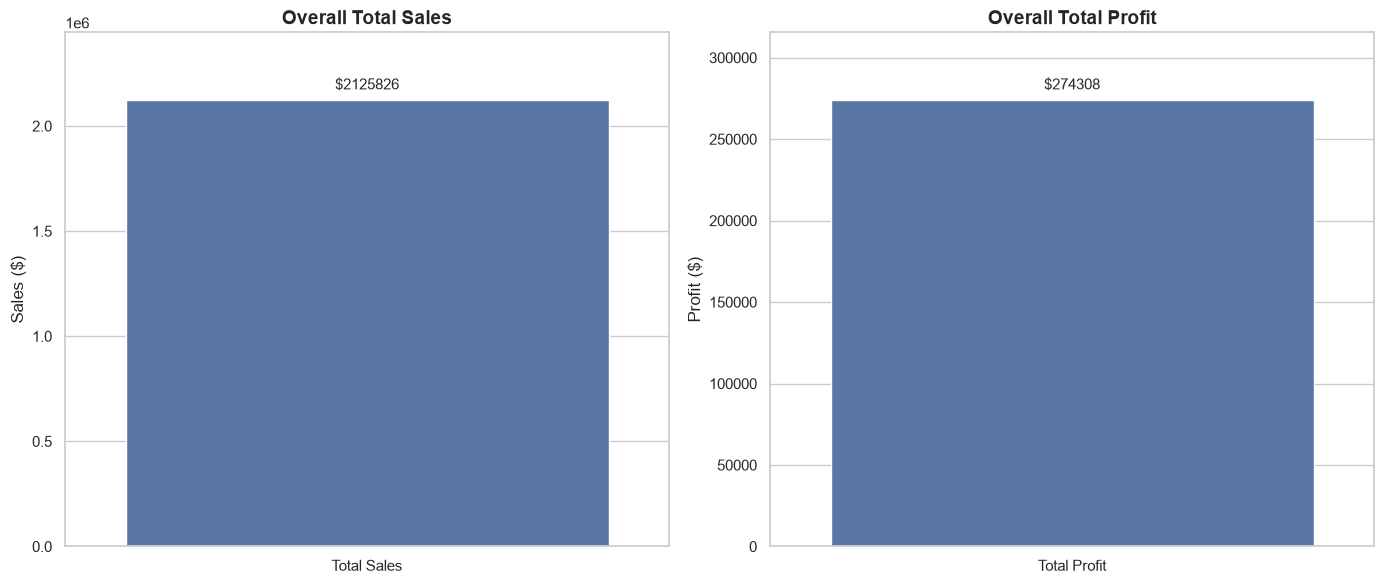

In [53]:

# Calculate overall sales and profit

total_sales = historical_df["Sales"].sum()
total_profit = historical_df["Profit"].sum()

# Create two bar charts

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sales chart

sns.barplot(
    x=["Total Sales"],
    y=[total_sales],
    ax=axes[0]
)

axes[0].set_title("Overall Total Sales", fontsize=14, fontweight="bold")
axes[0].set_ylabel("Sales ($)", fontsize=12)
axes[0].bar_label(
    axes[0].containers[0],
    fmt="$%.0f",
    fontsize=11,
    padding=5
)
axes[0].set_ylim(0, total_sales * 1.15)

# Profit chart

sns.barplot(
    x=["Total Profit"],
    y=[total_profit],
    ax=axes[1]
)

axes[1].set_title("Overall Total Profit", fontsize=14, fontweight="bold")
axes[1].set_ylabel("Profit ($)", fontsize=12)
axes[1].bar_label(
    axes[1].containers[0],
    fmt="$%.0f",
    fontsize=11,
    padding=5
)
axes[1].set_ylim(0, total_profit * 1.15)

plt.tight_layout()

# Save the visualization

plt.savefig(
    "../visualizations/overall_sales_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


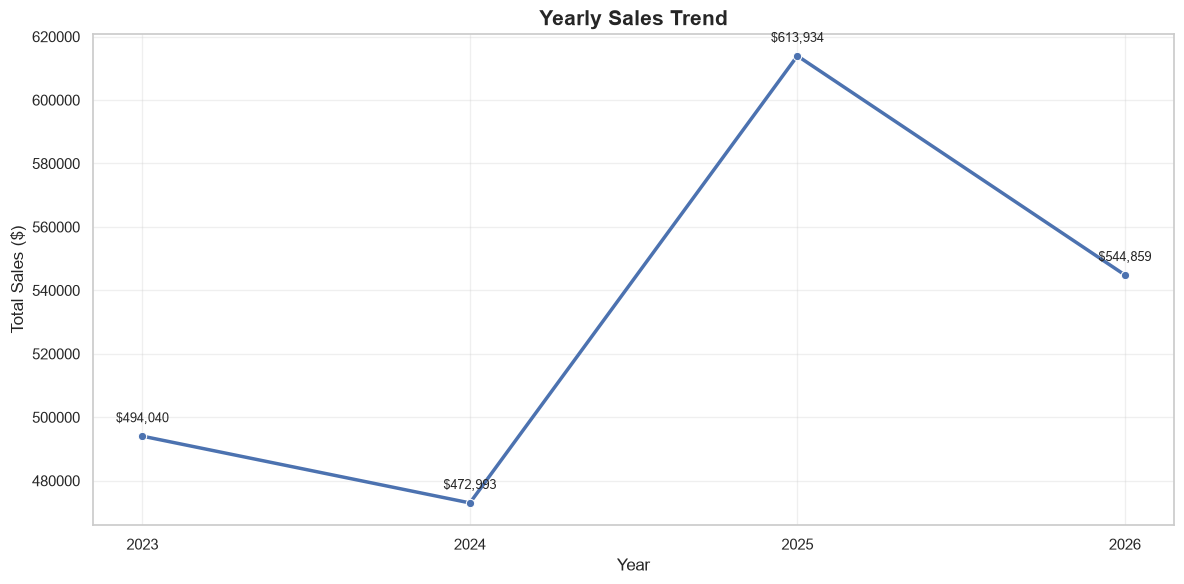

In [54]:

# Calculate yearly sales

yearly_sales = historical_df.groupby("Order Year")["Sales"].sum().reset_index()

# Create yearly sales trend chart

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_sales,
    x="Order Year",
    y="Sales",
    marker="o",
    linewidth=2.5
)

plt.title("Yearly Sales Trend", fontsize=15, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)
plt.xticks(yearly_sales["Order Year"])
plt.grid(True, alpha=0.3)

# Add sales value labels

for x, y in zip(yearly_sales["Order Year"], yearly_sales["Sales"]):
    plt.annotate(
        f"${y:,.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/yearly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


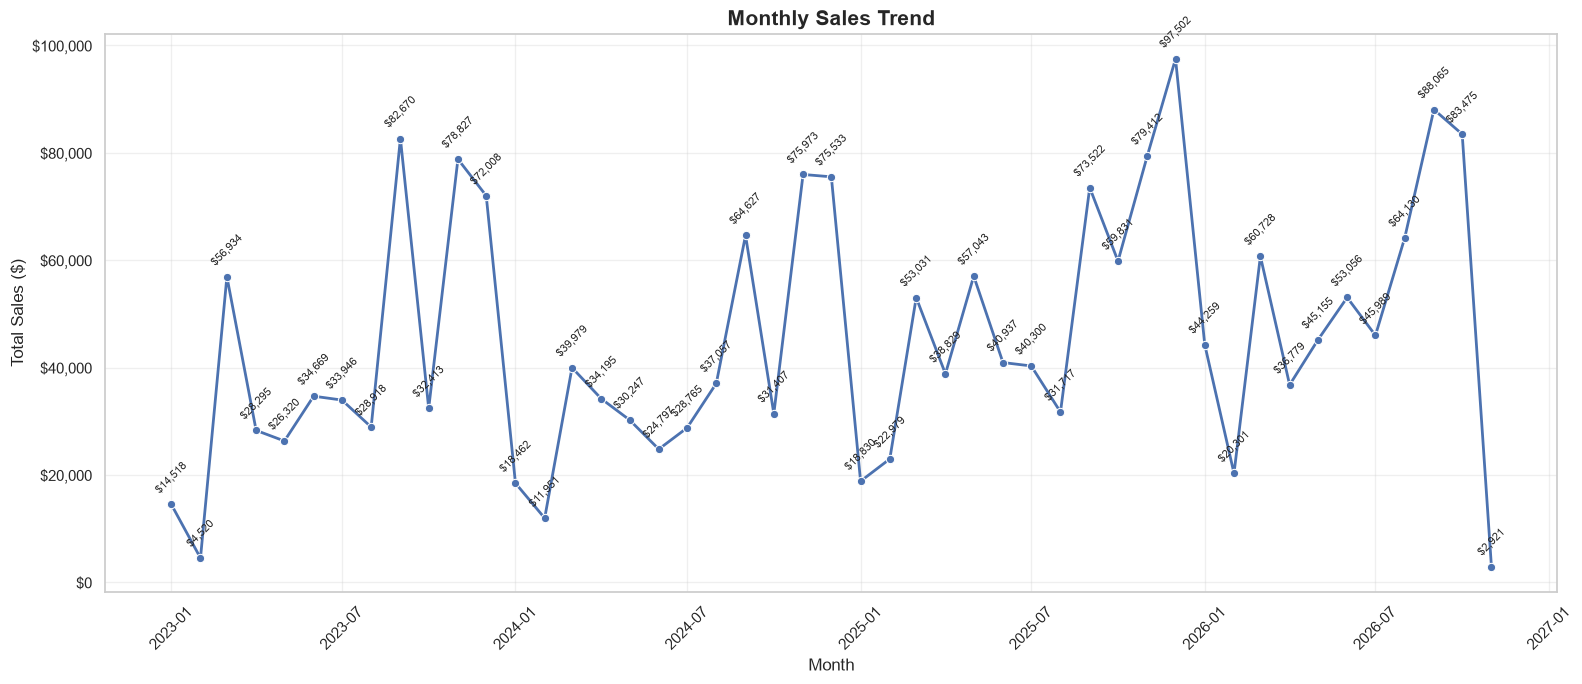

In [55]:

# Create a year-month column

monthly_sales = historical_monthly_performance.copy()

monthly_sales["Year_Month"] = pd.to_datetime({
    "year": monthly_sales["Order Year"],
    "month": monthly_sales["Order Month"],
    "day": 1
})

# Sort data chronologically

monthly_sales = monthly_sales.sort_values("Year_Month")

# Create monthly sales trend chart

plt.figure(figsize=(16, 7))

ax = sns.lineplot(
    data=monthly_sales,
    x="Year_Month",
    y="Total_Sales",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend", fontsize=15, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add sales values to every data point

for x, y in zip(monthly_sales["Year_Month"], monthly_sales["Total_Sales"]):
    ax.annotate(
        f"${y:,.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
        rotation=45
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


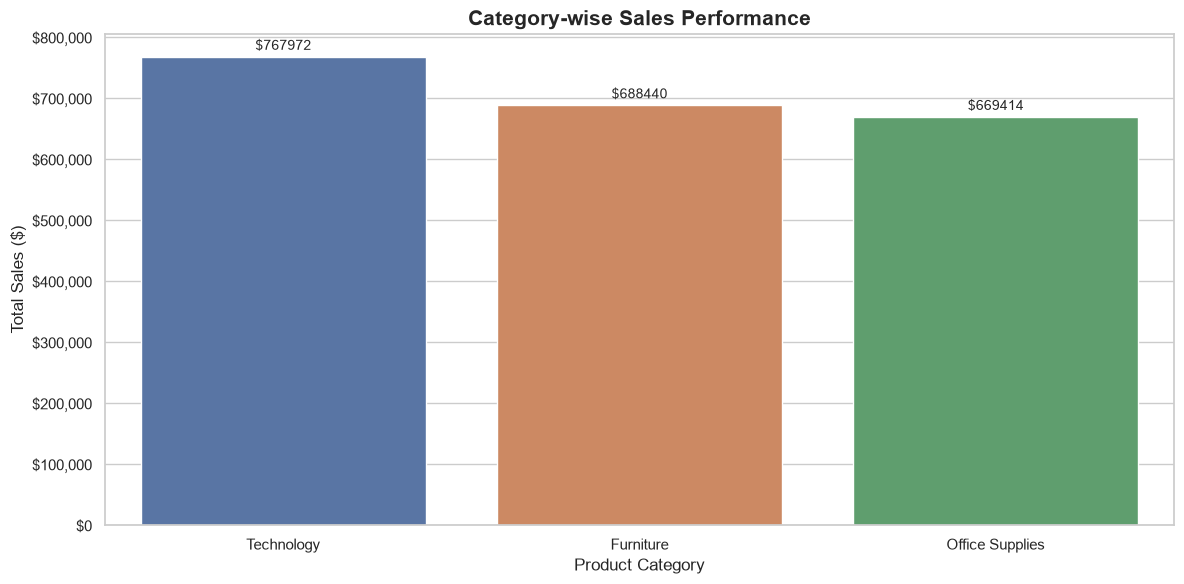

In [56]:

# Visualize sales by product category

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=category_performance,
    x="Category",
    y="Total_Sales",
    hue="Category",
    legend=False
)

plt.title("Category-wise Sales Performance", fontsize=15, fontweight="bold")
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add sales values above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/category_wise_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


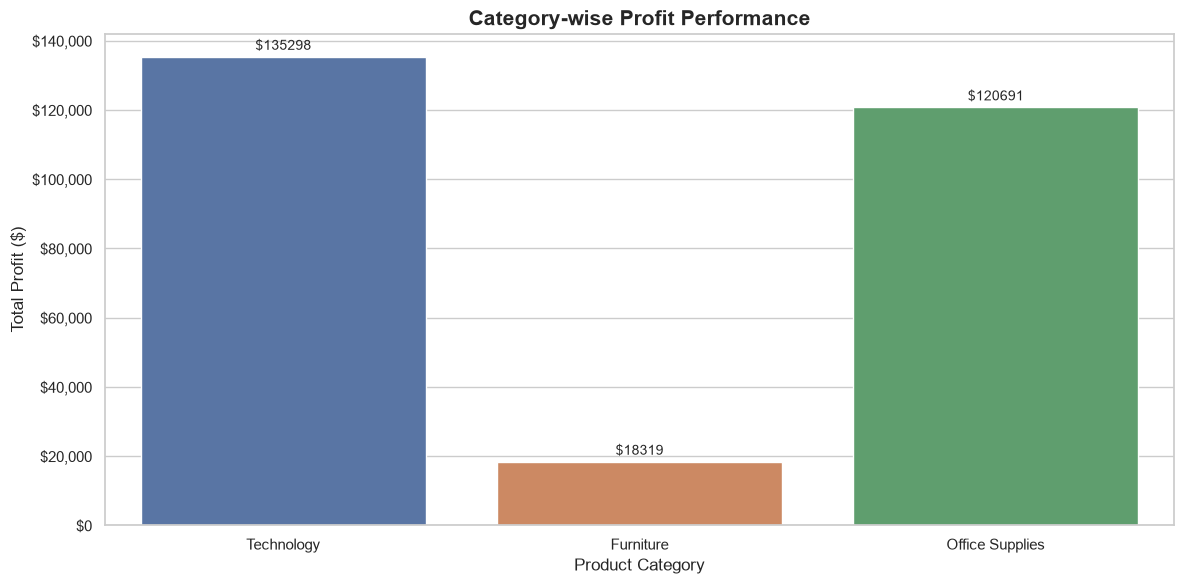

In [57]:

# Visualize profit by product category

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=category_performance,
    x="Category",
    y="Total_Profit",
    hue="Category",
    legend=False
)

plt.title("Category-wise Profit Performance", fontsize=15, fontweight="bold")
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add profit values above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/category_wise_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


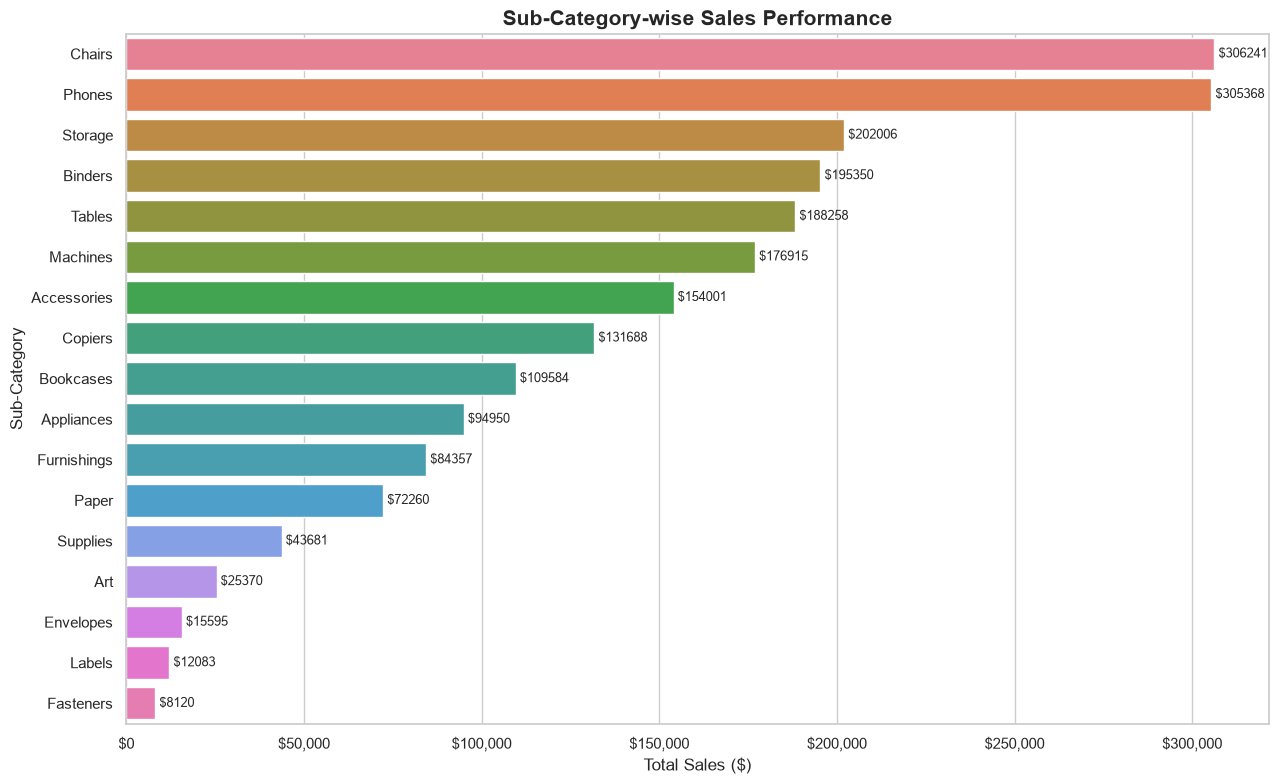

In [58]:

# Visualize sales by product sub-category

subcategory_sales = subcategory_performance.sort_values(
    by="Total_Sales",
    ascending=False
)

plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=subcategory_sales,
    x="Total_Sales",
    y="Sub-Category",
    hue="Sub-Category",
    legend=False
)

plt.title("Sub-Category-wise Sales Performance", fontsize=15, fontweight="bold")
plt.xlabel("Total Sales ($)", fontsize=12)
plt.ylabel("Sub-Category", fontsize=12)

# Format x-axis values as currency

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add sales values beside all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/subcategory_wise_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


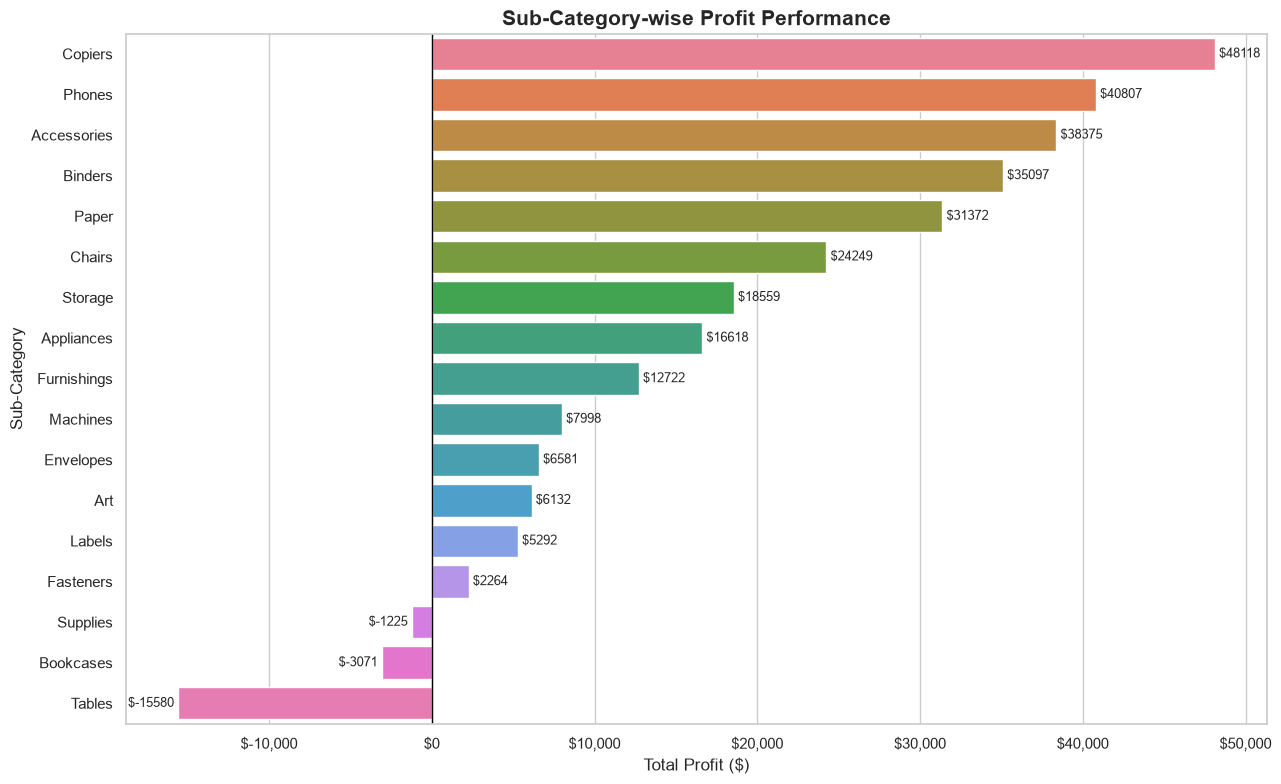

In [59]:

# Visualize profit by product sub-category

subcategory_profit = subcategory_performance.sort_values(
    by="Total_Profit",
    ascending=False
)

plt.figure(figsize=(13, 8))

ax = sns.barplot(
    data=subcategory_profit,
    x="Total_Profit",
    y="Sub-Category",
    hue="Sub-Category",
    legend=False
)

plt.axvline(x=0, color="black", linewidth=1)

plt.title("Sub-Category-wise Profit Performance", fontsize=15, fontweight="bold")
plt.xlabel("Total Profit ($)", fontsize=12)
plt.ylabel("Sub-Category", fontsize=12)

# Format x-axis values as currency

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add profit values beside all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/subcategory_wise_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


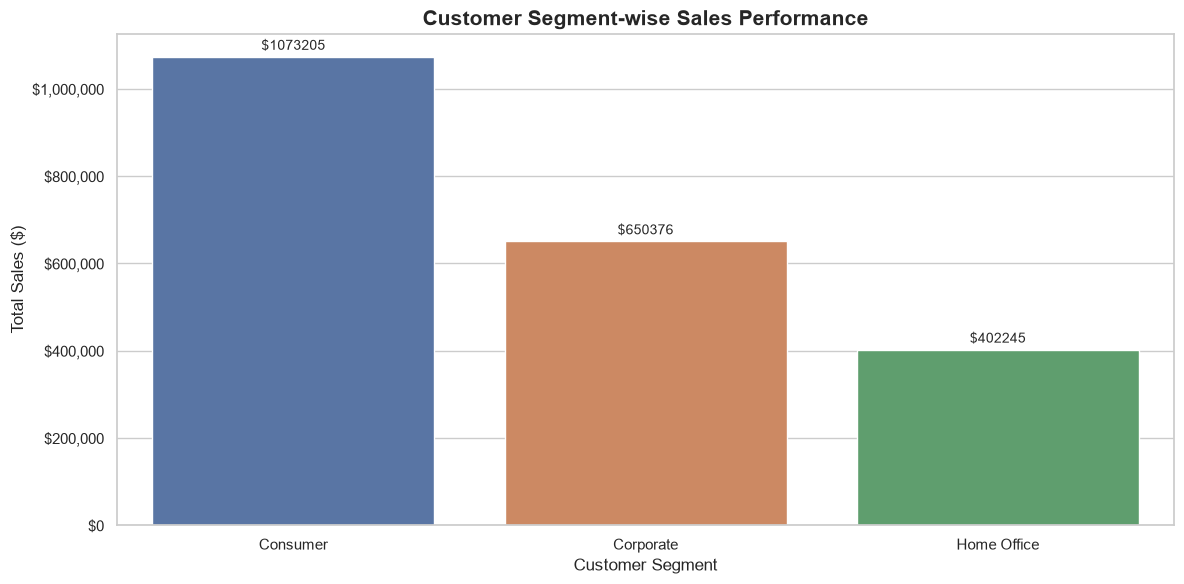

In [60]:

# Visualize sales by customer segment

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_performance,
    x="Segment",
    y="Total_Sales",
    hue="Segment",
    legend=False
)

plt.title("Customer Segment-wise Sales Performance", fontsize=15, fontweight="bold")
plt.xlabel("Customer Segment", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add sales values above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/customer_segment_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


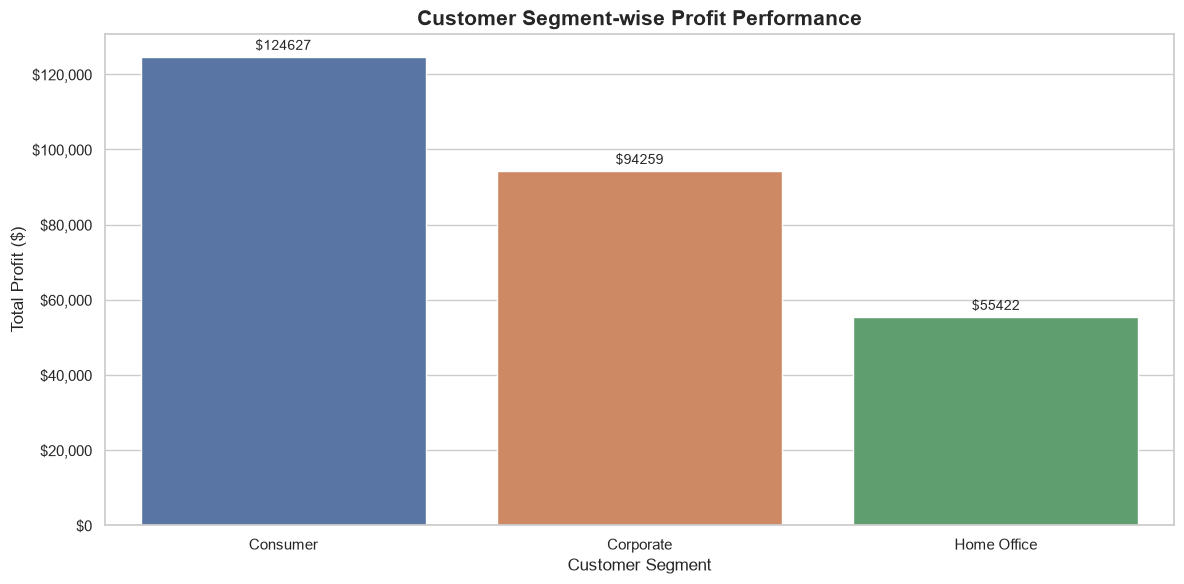

In [61]:

# Visualize profit by customer segment

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_performance,
    x="Segment",
    y="Total_Profit",
    hue="Segment",
    legend=False
)

plt.title("Customer Segment-wise Profit Performance", fontsize=15, fontweight="bold")
plt.xlabel("Customer Segment", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add profit values above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/customer_segment_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


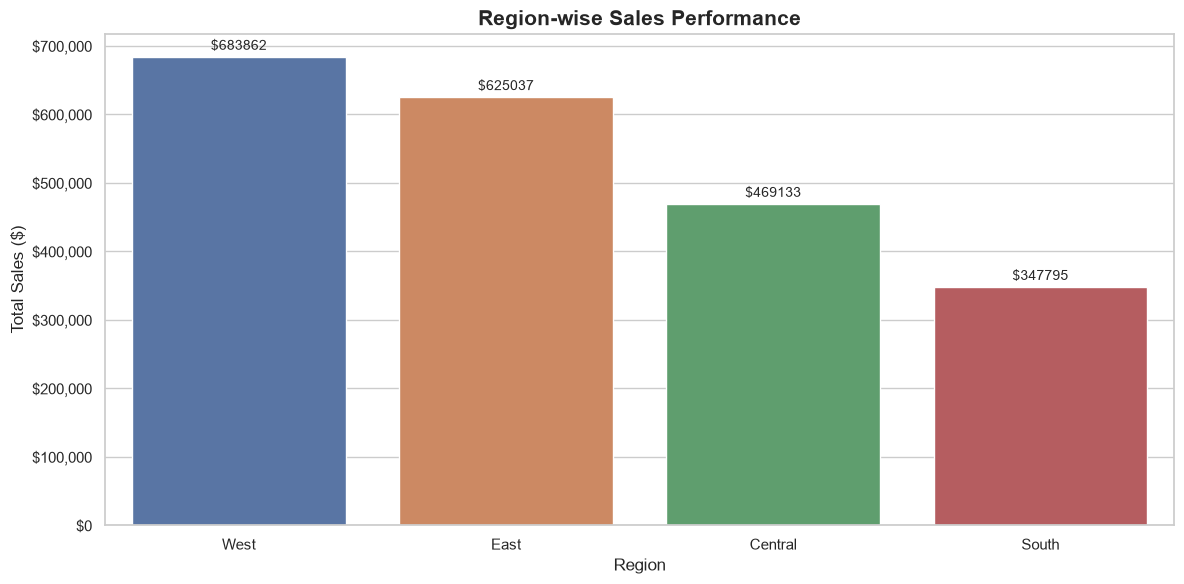

In [62]:

# Visualize sales by region

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=region_performance,
    x="Region",
    y="Total_Sales",
    hue="Region",
    legend=False
)

plt.title("Region-wise Sales Performance", fontsize=15, fontweight="bold")
plt.xlabel("Region", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add sales values above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/region_wise_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


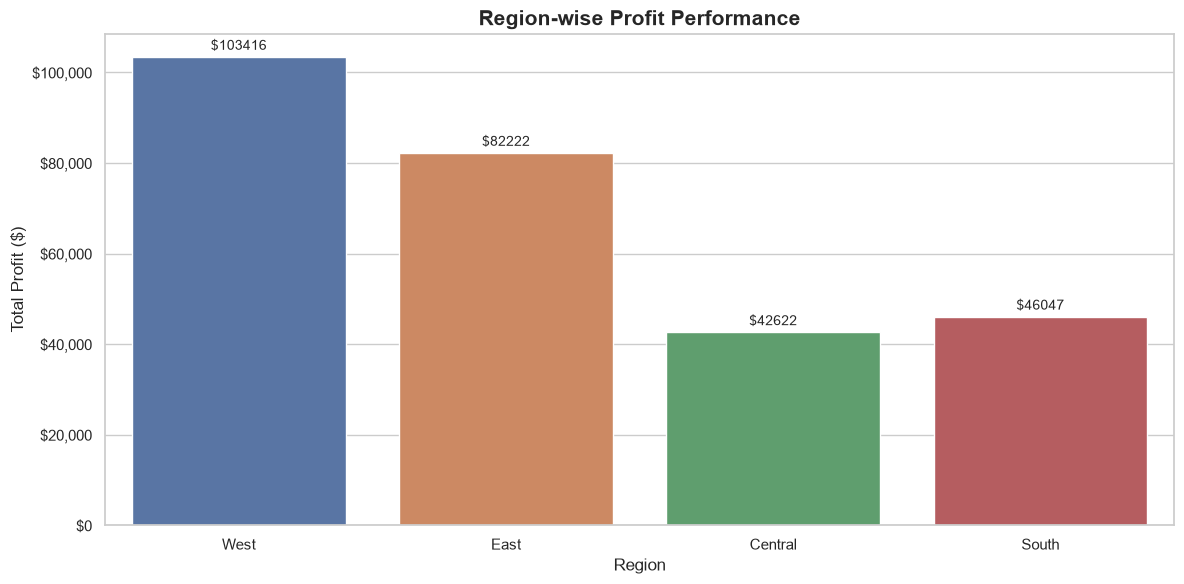

In [63]:

# Visualize profit by region

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=region_performance,
    x="Region",
    y="Total_Profit",
    hue="Region",
    legend=False
)

plt.title("Region-wise Profit Performance", fontsize=15, fontweight="bold")
plt.xlabel("Region", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add profit values above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/region_wise_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


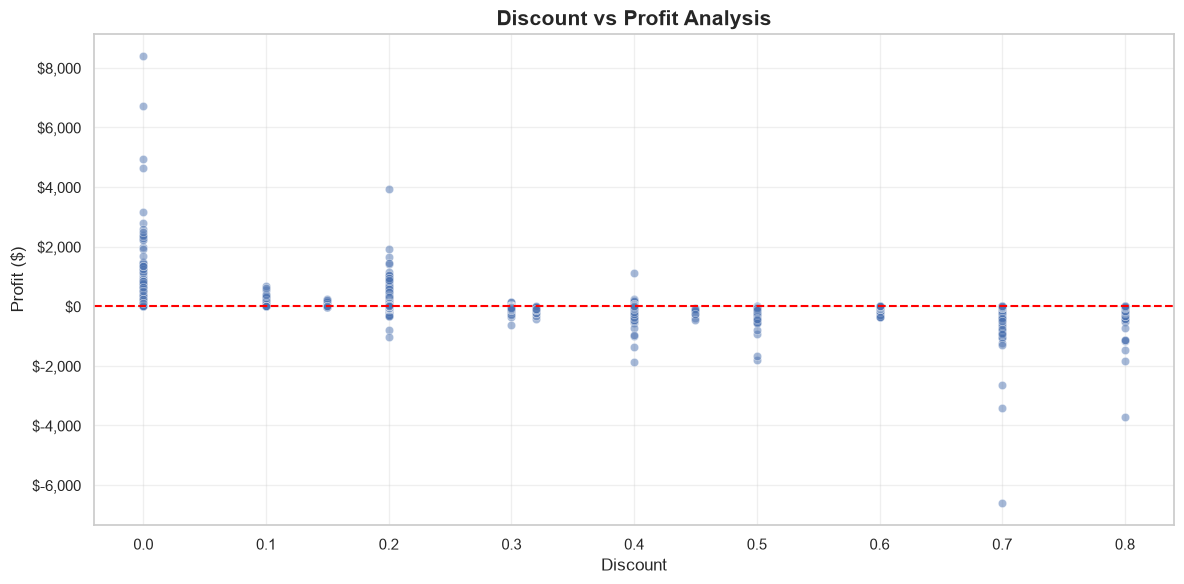

In [64]:

# Visualize relationship between discount and profit

plt.figure(figsize=(12, 6))

ax = sns.scatterplot(
    data=historical_df,
    x="Discount",
    y="Profit",
    alpha=0.5
)

plt.axhline(y=0, color="red", linestyle="--", linewidth=1.5)

plt.title("Discount vs Profit Analysis", fontsize=15, fontweight="bold")
plt.xlabel("Discount", fontsize=12)
plt.ylabel("Profit ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/discount_vs_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


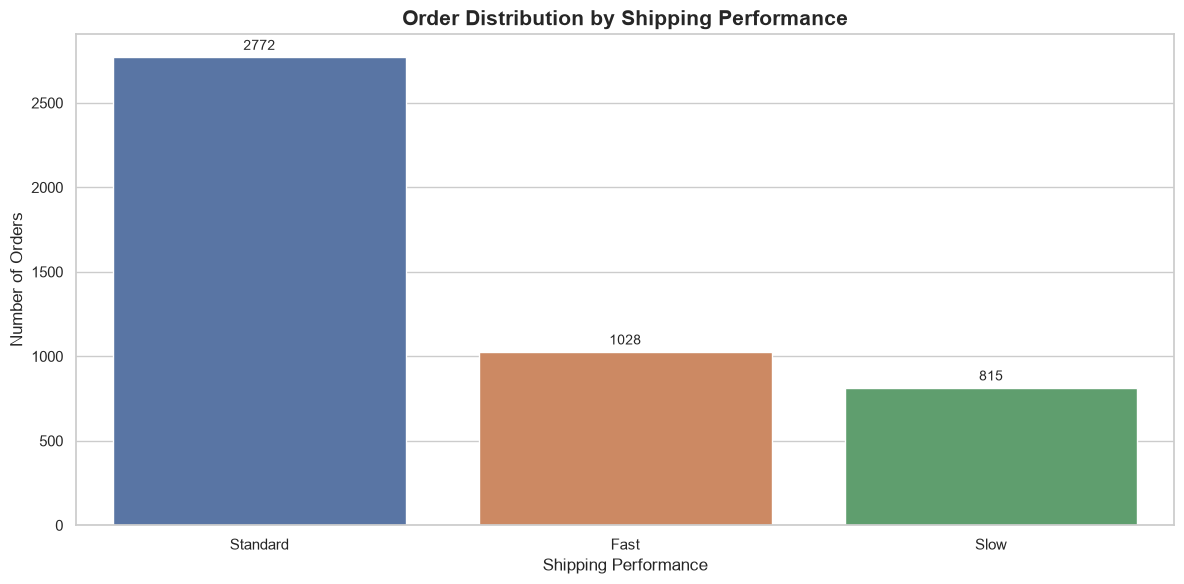

In [65]:

# Visualize order count by shipping performance

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=shipping_performance,
    x="Shipping Performance",
    y="Total_Orders",
    hue="Shipping Performance",
    legend=False
)

plt.title("Order Distribution by Shipping Performance", fontsize=15, fontweight="bold")
plt.xlabel("Shipping Performance", fontsize=12)
plt.ylabel("Number of Orders", fontsize=12)

# Add order counts above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/shipping_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


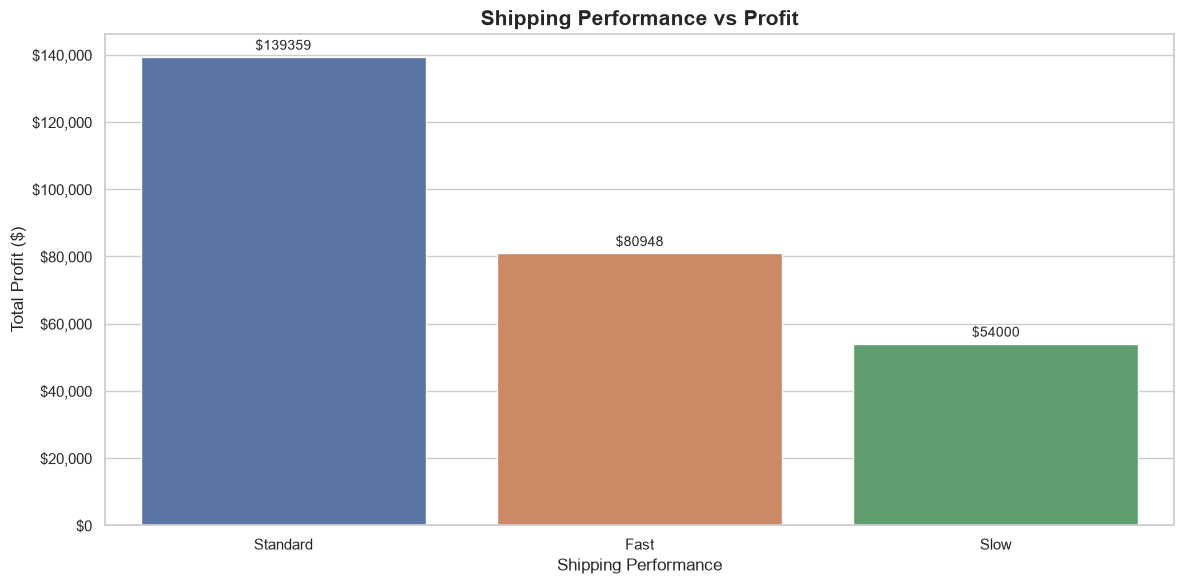

In [66]:

# Visualize profit by shipping performance

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=shipping_performance,
    x="Shipping Performance",
    y="Total_Profit",
    hue="Shipping Performance",
    legend=False
)

plt.title("Shipping Performance vs Profit", fontsize=15, fontweight="bold")
plt.xlabel("Shipping Performance", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

# Format y-axis values as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add profit values above all bars

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=10
    )

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/shipping_performance_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


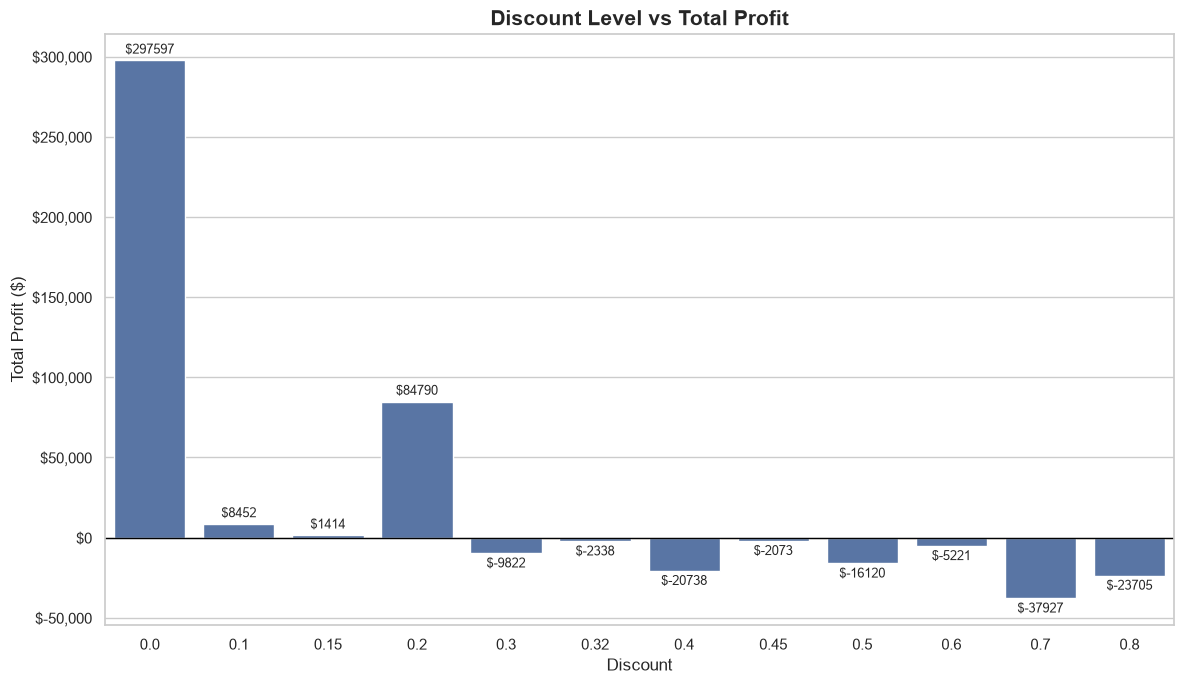

In [67]:

# Analyze profitability by discount level

discount_performance = historical_df.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate profit margin

discount_performance["Profit_Margin"] = (
    discount_performance["Total_Profit"] /
    discount_performance["Total_Sales"] * 100
)

# Sort discount levels

discount_performance = discount_performance.sort_values("Discount")

# Visualize profit by discount level

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=discount_performance,
    x="Discount",
    y="Total_Profit"
)

plt.title("Discount Level vs Total Profit", fontsize=15, fontweight="bold")
plt.xlabel("Discount", fontsize=12)
plt.ylabel("Total Profit ($)", fontsize=12)

# Format y-axis as currency

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x:,.0f}")
)

# Add profit values above every bar

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3,
        fontsize=9
    )

plt.axhline(y=0, color="black", linewidth=1)

plt.tight_layout()

# Save visualization

plt.savefig(
    "../visualizations/discount_level_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [68]:
%pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [69]:
import mysql.connector
from getpass import getpass

password = getpass("Enter MySQL root password: ")

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password=password,
    database="sales_analysis",
    connection_timeout=10
)

print("Connected successfully!")

Connected successfully!


In [70]:
import pandas as pd
from decimal import Decimal
import mysql.connector

# Load historical dataset
df = pd.read_csv("../data/processed/historical_sales.csv")

# Convert dates
df["Order Date"] = pd.to_datetime(df["Order Date"]).dt.date
df["Ship Date"] = pd.to_datetime(df["Ship Date"]).dt.date

# Convert decimal columns accurately
for col in ["Sales", "Profit", "Discount"]:
    df[col] = df[col].apply(
        lambda x: Decimal(str(x)).quantize(Decimal("0.01"))
    )

# Integer columns
for col in ["Row ID", "Quantity", "Shipping Duration",
             "Order Year", "Ship Year", "Order Month"]:
    df[col] = df[col].astype(int)

# Prepare records
records = [
    tuple(None if pd.isna(v) else v for v in row)
    for row in df.itertuples(index=False, name=None)
]

# Insert records
cursor = conn.cursor()

cursor.execute("TRUNCATE TABLE sales")

insert_query = """
INSERT INTO sales VALUES (
    %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s, %s, %s, %s, %s,
    %s, %s, %s, %s
)
"""

cursor.executemany(insert_query, records)
conn.commit()

print("Records inserted:", cursor.rowcount)

cursor.close()

Records inserted: 9256


True

In [71]:
cursor = conn.cursor()

cursor.execute("""
SELECT COUNT(*), SUM(Sales), SUM(Profit)
FROM sales
""")

print(cursor.fetchone())

cursor.close()

(9256, Decimal('2125826.05'), Decimal('274307.38'))


True

In [72]:
# Validate SQL data integrity against historical dataset

cursor = conn.cursor()

cursor.execute("""
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT `Order ID`) AS total_orders,
    COUNT(DISTINCT `Customer ID`) AS total_customers,
    SUM(Quantity) AS total_quantity,
    MIN(`Order Date`) AS first_order,
    MAX(`Order Date`) AS last_order,
    SUM(CASE WHEN `Ship Date` < `Order Date` THEN 1 ELSE 0 END) AS invalid_shipping_dates
FROM sales
""")

sql_results = cursor.fetchone()

print("SQL Summary:", sql_results)

# Validate SQL totals against historical dataset

assert sql_results[0] == len(historical_df), "SQL record count mismatch"
assert sql_results[1] == historical_df["Order ID"].nunique(), "SQL order count mismatch"
assert sql_results[2] == historical_df["Customer ID"].nunique(), "SQL customer count mismatch"
assert int(sql_results[3]) == int(historical_df["Quantity"].sum()), "SQL quantity mismatch"

assert sql_results[4] == historical_df["Order Date"].min().date(), "SQL first order date mismatch"
assert sql_results[5] == historical_df["Order Date"].max().date(), "SQL last order date mismatch"

# Validate SQL shipping dates

print("Invalid SQL Shipping Date Records:", sql_results[6])

assert sql_results[6] == 0, "Invalid shipping dates found in SQL"

print("\nSQL data integrity validation passed.")

cursor.close()

SQL Summary: (9256, 4615, 803, Decimal('35017'), datetime.date(2023, 1, 3), datetime.date(2026, 11, 1), Decimal('0'))
Invalid SQL Shipping Date Records: 0

SQL data integrity validation passed.


True

In [74]:

# Validate and compare SQL and Pandas overall business metrics

pandas_metrics = {
    "Total Sales": historical_df["Sales"].sum(),
    "Total Profit": historical_df["Profit"].sum(),
    "Total Quantity": historical_df["Quantity"].sum()
}

sql_metrics = pd.read_sql("""
    SELECT
        SUM(Sales) AS `Total Sales`,
        SUM(Profit) AS `Total Profit`,
        SUM(Quantity) AS `Total Quantity`
    FROM sales
""", conn).iloc[0]

# Compare SQL and Pandas values

comparison_df = pd.DataFrame({
    "Pandas Value": pandas_metrics,
    "SQL Value": sql_metrics
})

comparison_df["Difference (SQL - Pandas)"] = (
    comparison_df["SQL Value"] - comparison_df["Pandas Value"]
)

print("SQL vs Pandas Comparison")
display(comparison_df)

# Validate results
for metric in pandas_metrics:
    assert np.isclose(
        pandas_metrics[metric],
        sql_metrics[metric],
        atol=0.01
    ), f"{metric} mismatch"

print("SQL and Pandas validation passed.")


SQL vs Pandas Comparison


C:\Users\DELL\AppData\Local\Temp\ipykernel_9396\3603404720.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  sql_metrics = pd.read_sql("""


,Pandas Value,SQL Value,Difference (SQL - Pandas)
Total Sales,2.125826e+06,2125826.05,-0.1965
Total Profit,2.743078e+05,274307.38,-0.4009
Total Quantity,3.501700e+04,35017.00,0.0000


SQL and Pandas validation passed.



## Final Business Insights and Conclusion

### Key Business Insights

- Technology generated the highest sales and profit.
- Office Supplies achieved the highest category profit margin.
- Tables recorded the largest subcategory loss.
- Consumer customers contributed the highest sales and total profit.
- Corporate customers achieved the highest profit margin.
- West was the strongest region in terms of sales and profit.
- September consistently recorded strong monthly sales.
- Higher discounts were associated with negative profitability.
- High sales volume did not always translate into high profitability.

### Business Recommendations

- Review pricing and cost structures for loss-making products.
- Optimize discount strategies to protect profit margins.
- Investigate weaker regional profitability.
- Focus on profitable customer relationships.
- Use monthly sales trends for inventory and marketing planning.

### Conclusion

This project demonstrates how Python, Pandas, NumPy, Matplotlib, Seaborn, and MySQL can be used together to perform comprehensive sales data analysis.

Python was used for data cleaning, exploratory data analysis, business analysis, and visualization. MySQL was used to perform structured business analysis and validate analytical results.

The analysis identified meaningful patterns in product performance, customer behavior, regional sales, discount strategies, and profitability.

Overall, this project demonstrates practical data analysis skills and provides a foundation for data-driven business decision-making.
